# 📌 Credit Risk / Loan Default Decisioning System
### End-to-End, Business-First Analytics Project

---

## 🔍 Project Overview

This notebook implements an **end-to-end credit risk decisioning pipeline** using historical loan data.
The objective is **not just to predict loan default**, but to **support real lending decisions** such as:

- ✅ Approve
- 🟡 Manual Review
- ❌ Reject

The project is designed to mirror how **risk analytics teams in banks and fintech companies** build, evaluate, and operationalize credit risk models, with a strong emphasis on **business impact, explainability, and decision-making**.

---

## 🎯 Business Problem

Lending decisions involve **asymmetric risk**:

- Approving a bad borrower can lead to **significant financial loss**
- Rejecting a good borrower leads to **missed revenue and customer churn**

The goal of this project is to:

> **Estimate the probability of loan default for each applicant and translate that risk into actionable business decisions aligned with risk appetite.**

---

## 🧠 Key Design Principles

- **Business-first thinking:** models output probabilities; decisions are made via business rules.
- **Clear separation of concerns:** data ingestion, cleaning, feature engineering, modeling, evaluation, and decisioning are handled in separate phases.
- **Leakage prevention:** only information available at loan decision time is used, and missing values are imputed using training data only.
- **Cost-sensitive evaluation:** models are compared using expected financial loss, not just accuracy.
- **Explainability & governance:** interpretable features, a baseline model, and SHAP analysis support auditability.

---

## 🗂 Dataset

- **Source:** Lending Club loan performance dataset (via Kaggle)
- **Nature:** Historical consumer loan data (2007–2018)
- **Target Variable:** Binary default outcome
  - `1` → Default (Charged Off / Defaulted)
  - `0` → Non-default (Fully Paid)

---

## 🧱 Pipeline Structure

1. **Phase 1 – Data Ingestion:** chunk-based loading of the raw loan data.
2. **Phase 2 – Data Cleaning & Leakage Prevention:** binary target definition, removal of post-loan columns, and missing value handling.
3. **Phase 3 – Feature Engineering:** interpretable risk signals capturing repayment capacity, credit history strength, debt burden, and loan structure stress.
4. **Phase 4 – Modeling:** Logistic Regression (baseline), Random Forest, and XGBoost, all producing a **probability of default (PD)**.
5. **Phase 5 – Evaluation & Business Trade-offs:** ROC-AUC, Precision–Recall, confusion matrices at business thresholds, and cost-sensitive comparison.
6. **Phase 6 – Decision Engine:** conversion of PDs into Approve / Review / Reject decisions and portfolio-level impact analysis.
7. **Phase 7 – Explainability:** SHAP analysis to identify the key drivers of default risk.

---

## 📊 Key Outputs

- Probability of default (PD) per loan
- Approve / Review / Reject decision per loan
- Default rate within each decision bucket
- Expected financial loss comparison across models
- SHAP-based explanation of the main risk drivers
- Final decision dataset suitable for operations or dashboards

---

## 🏦 How This Would Be Used in Practice

- Models score loan applications as they arrive
- Risk thresholds are controlled by business and risk teams
- Policies can be tightened or relaxed **without retraining models**
- Logistic Regression serves as an interpretable governance benchmark
- Tree-based models provide enhanced risk separation

# **Setup and Imports**  

In [2]:
import pandas as pd
import numpy as np
import os

# **PHASE 1: DATA INGESTION**

In [3]:
DATA_PATH = "/kaggle/input/datasets/wordsforthewise/lending-club/accepted_2007_to_2018Q4.csv.gz"

chunk_size = 200_000  # safe chunk size
chunks = []

for chunk in pd.read_csv(DATA_PATH, compression="gzip", chunksize=chunk_size, low_memory=False):
    chunks.append(chunk)

raw_df = pd.concat(chunks, ignore_index=True)

print("Raw data loaded")
print("Shape:", raw_df.shape)


Raw data loaded
Shape: (2260701, 151)


In [4]:
raw_df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2260701 entries, 0 to 2260700
Columns: 151 entries, id to settlement_term
dtypes: float64(113), object(38)
memory usage: 2.5+ GB


In [6]:
raw_df.describe()

,member_id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,fico_range_low,...,deferral_term,hardship_amount,hardship_length,hardship_dpd,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,settlement_amount,settlement_percentage,settlement_term
count,0.0,2.260668e+06,2.260668e+06,2.260668e+06,2.260668e+06,2.260668e+06,2.260664e+06,2.258957e+06,2.260639e+06,2.260668e+06,...,10917.0,10917.000000,10917.0,10917.000000,8651.000000,10917.000000,10917.000000,34246.000000,34246.000000,34246.000000
mean,NaN,1.504693e+04,1.504166e+04,1.502344e+04,1.309283e+01,4.458068e+02,7.799243e+04,1.882420e+01,3.068792e-01,6.985882e+02,...,3.0,155.045981,3.0,13.743886,454.798089,11636.883942,193.994321,5010.664267,47.780365,13.191322
std,NaN,9.190245e+03,9.188413e+03,9.192332e+03,4.832138e+00,2.671735e+02,1.126962e+05,1.418333e+01,8.672303e-01,3.301038e+01,...,0.0,129.040594,0.0,9.671178,375.385500,7625.988281,198.629496,3693.122590,7.311822,8.159980
min,NaN,5.000000e+02,5.000000e+02,0.000000e+00,5.310000e+00,4.930000e+00,0.000000e+00,-1.000000e+00,0.000000e+00,6.100000e+02,...,3.0,0.640000,3.0,0.000000,1.920000,55.730000,0.010000,44.210000,0.200000,0.000000
25%,NaN,8.000000e+03,8.000000e+03,8.000000e+03,9.490000e+00,2.516500e+02,4.600000e+04,1.189000e+01,0.000000e+00,6.750000e+02,...,3.0,59.440000,3.0,5.000000,175.230000,5627.000000,44.440000,2208.000000,45.000000,6.000000
50%,NaN,1.290000e+04,1.287500e+04,1.280000e+04,1.262000e+01,3.779900e+02,6.500000e+04,1.784000e+01,0.000000e+00,6.900000e+02,...,3.0,119.140000,3.0,15.000000,352.770000,10028.390000,133.160000,4146.110000,45.000000,14.000000
75%,NaN,2.000000e+04,2.000000e+04,2.000000e+04,1.599000e+01,5.933200e+02,9.300000e+04,2.449000e+01,0.000000e+00,7.150000e+02,...,3.0,213.260000,3.0,22.000000,620.175000,16151.890000,284.190000,6850.172500,50.000000,18.000000
max,NaN,4.000000e+04,4.000000e+04,4.000000e+04,3.099000e+01,1.719830e+03,1.100000e+08,9.990000e+02,5.800000e+01,8.450000e+02,...,3.0,943.940000,3.0,37.000000,2680.890000,40306.410000,1407.860000,33601.000000,521.350000,181.000000


# Initial Data Inspection

## 📊 Dataset Summary

- ✅ **Dataset Loaded Successfully**
- 📁 Total Records: **2,260,701**
- 📌 Total Features: **151**
- 🔢 Numerical Features: **113**
- 📝 Categorical Features: **38**
- 💾 Dataset Size: **~2.5 GB**

## 🔍Initial Observations

- Dataset contains both numerical and categorical features.
- Loan information includes amount, interest rate, term, grade, and applicant details.
- Dataset is ready for preprocessing and feature engineering.

# **PHASE 2: DATA CLEANING & LEAKAGE PREVENTION**

## 🎯 Objective

The objective of this phase is to prepare the raw loan dataset for machine learning by:

- **Creating** the target variable.
- **Removing** data leakage.
- **Handling** missing values.
- **Removing** irrelevant features.
- **Preparing** a clean dataset for feature engineering.

## Step 1: Define Binary Target

In [7]:
raw_df["loan_status"].value_counts()

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64

### Why Only Three Loan Statuses?

The original dataset contains multiple loan statuses such as **Current**, **Late**, and **In Grace Period**. These represent loans whose final outcome is not yet known.

For binary classification, only loans with a final outcome are retained:

- ✅ Fully Paid → Non-Default (0)
- ❌ Charged Off → Default (1)
- ❌ Default → Default (1)

This prevents data leakage and creates a reliable target variable.

In [8]:
raw_df.shape

(2260701, 151)

In [9]:
valid_status = ["Fully Paid", "Charged Off", "Default"]

raw_df = raw_df[raw_df["loan_status"].isin(valid_status)]

raw_df["default_flag"] = raw_df["loan_status"].apply(
    lambda x: 1 if x in ["Charged Off", "Default"] else 0
)


In [10]:
raw_df.shape

(1345350, 152)

## Step 2: Remove Leakage Columns

In [11]:
leakage_cols = [
    "total_pymnt", "total_pymnt_inv",
    "total_rec_prncp", "total_rec_int",
    "recoveries", "collection_recovery_fee",
    "last_pymnt_d", "last_pymnt_amnt",
    "next_pymnt_d"
]

raw_df.drop(columns=[c for c in leakage_cols if c in raw_df.columns],
            inplace=True)


In [12]:
print("Columns after leakage removal:", raw_df.shape[1])

removed = len(leakage_cols)
print("Leakage columns removed:", removed)

Columns after leakage removal: 143
Leakage columns removed: 9


### ✅ Result

The selected leakage columns were successfully removed.

- Columns before removal: **152**
- Columns after removal: **143**
- Leakage columns removed: **9**

Removing these post-loan information columns prevents data leakage and ensures that the model learns only from information available at the time of loan approval, resulting in realistic and unbiased predictions.

## Step 3: Handle Missing Values (SAFE & EXPLAINABLE)

### 🎯 Objective

Many machine learning algorithms cannot handle missing values directly.

In this step, missing numerical values will be replaced using the median, while missing categorical values will be replaced with **"Unknown"**. This preserves useful information without introducing data leakage.

In [13]:
raw_df[["annual_inc", "emp_length"]].isnull().sum()

annual_inc        0
emp_length    78516
dtype: int64

In [14]:
if "emp_length" in raw_df.columns:
    raw_df["emp_length"] = raw_df["emp_length"].fillna("Unknown")


In [15]:
raw_df["emp_length"].isnull().sum()

np.int64(0)

### ✅ Result

Missing values in **emp_length** were successfully replaced with **"Unknown"**.

The **annual_inc** feature contained no missing values, so no imputation was required.

This approach preserves the dataset while avoiding unnecessary modifications and maintaining data quality.

## Step 4: Drop High-Missing Columns

## 🎯 Objective

Some features contain more than **50% missing values**, making them unreliable for model training.

In this step, such columns are removed to:

- Reduce unnecessary missing data.
- Improve model quality.
- Simplify feature engineering.
- Keep only informative features.

In [16]:
missing_ratio = raw_df.isnull().mean()
high_missing = missing_ratio[missing_ratio > 0.5].index

print("Columns with >50% missing values:", len(high_missing))
print(high_missing.tolist())

Columns with >50% missing values: 57
['member_id', 'desc', 'mths_since_last_delinq', 'mths_since_last_record', 'mths_since_last_major_derog', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m', 'mths_since_recent_bc_dlq', 'mths_since_recent_revol_delinq', 'revol_bal_joint', 'sec_app_fico_range_low', 'sec_app_fico_range_high', 'sec_app_earliest_cr_line', 'sec_app_inq_last_6mths', 'sec_app_mort_acc', 'sec_app_open_acc', 'sec_app_revol_util', 'sec_app_open_act_il', 'sec_app_num_rev_accts', 'sec_app_chargeoff_within_12_mths', 'sec_app_collections_12_mths_ex_med', 'sec_app_mths_since_last_major_derog', 'hardship_type', 'hardship_reason', 'hardship_status', 'deferral_term', 'hardship_amount', 'hardship_start_date', 'hardship_end_date', 'payment_plan_start_date', 'hardship_length'

In [17]:
missing_ratio = raw_df.isnull().mean()
high_missing = missing_ratio[missing_ratio > 0.5].index

raw_df.drop(columns=high_missing, inplace=True)


In [18]:
print("Columns after dropping:", raw_df.shape[1])
print("Columns removed:", len(high_missing))

Columns after dropping: 86
Columns removed: 57


## ✅ Result

Columns with more than **50% missing values** were successfully removed.

- **57** high-missing columns were dropped.
- The total number of features was reduced from **143** to **86**.
- Removing these columns reduces noise and improves data quality.
- The dataset is now cleaner and more suitable for feature engineering and model training.

## Final Sanity Check

In [19]:
print("Cleaned data shape:", raw_df.shape)
print("Default rate:", raw_df["default_flag"].mean())


Cleaned data shape: (1345350, 86)
Default rate: 0.19964990522912254


## ✅ Result

The dataset passed the final sanity checks.

- The cleaned dataset contains only relevant features.
- The target variable (**default_flag**) was successfully created.
- High-missing and leakage columns were removed.
- Missing values in selected features were handled.
- The dataset is now ready for feature engineering and model training.

## SAVE CLEANED OUTPUT

## 💾 Save Cleaned Dataset

The cleaned dataset is saved so that feature engineering and model training can start from a consistent and preprocessed version of the data.

This avoids repeating preprocessing steps and improves workflow efficiency.

In [20]:
OUTPUT_PATH = "/kaggle/working/cleaned_data.csv"
raw_df.to_csv(OUTPUT_PATH, index=False)

print("Cleaned data saved.")


Cleaned data saved.


In [21]:
import os

print("File exists:", os.path.exists(OUTPUT_PATH))
print("Saved file:", OUTPUT_PATH)

File exists: True
Saved file: /kaggle/working/cleaned_data.csv


## ✅ Result

The cleaned dataset was successfully saved.

- Dataset Name: **cleaned_data.csv**
- Location: **/kaggle/working/**
- The saved dataset will be used in the Feature Engineering phase.
- Preprocessing does not need to be repeated in future experiments.

# **PHASE 3 — FEATURE ENGINEERING**

## i. LOAD CLEANED DATA

### 🎯 Objective

Load the cleaned dataset saved in the previous phase to continue feature engineering from a consistent and preprocessed version of the data.

In [22]:


CLEAN_PATH = "/kaggle/working/cleaned_data.csv"
df = pd.read_csv(CLEAN_PATH)

print(df.shape)


(1345350, 86)


## ✅ Result

The cleaned dataset was successfully loaded.

- Dataset Shape: **(1,345,350, 86)**
- The cleaned dataset generated in Phase 2 has been successfully imported.
- All preprocessing steps have been preserved.
- The dataset is now ready for feature engineering.

## ii. FEATURE ENGINEERING

We’ll create three categories of features:

1. Capacity to repay

2. Credit behavior

3. Loan structure stress

Each feature has a clear business meaning.

#### 1. Capacity to Repay

### Income-to-Loan Ratio & Installment Burden

These features estimate the borrower's repayment capacity.

- **Income-to-Loan Ratio:** Annual income divided by loan amount.
- **Installment-to-Income Ratio:** Monthly installment divided by monthly income.

Higher income support and lower installment burden generally indicate stronger repayment ability.

In [23]:
# ▶ Income-to-Loan Ratio
df["income_to_loan_ratio"] = df["annual_inc"] / df["loan_amnt"]

# ▶ Installment Burden (Monthly Stress)
df["installment_to_income"] = (
    df["installment"] / (df["annual_inc"] / 12)
)

print("✅ Capacity to Repay features created")

df[[
    "annual_inc",
    "loan_amnt",
    "installment",
    "income_to_loan_ratio",
    "installment_to_income"
]].head()

✅ Capacity to Repay features created


,annual_inc,loan_amnt,installment,income_to_loan_ratio,installment_to_income
0,55000.0,3600.0,123.03,15.277778,0.026843
1,65000.0,24700.0,820.28,2.631579,0.151436
2,63000.0,20000.0,432.66,3.150000,0.082411
3,104433.0,10400.0,289.91,10.041635,0.033312
4,34000.0,11950.0,405.18,2.845188,0.143005


#### 2. Credit History Strength

### Credit History Features

These features evaluate the borrower's past credit behavior and repayment experience.

- **Credit History Years:** Number of years since the borrower's first credit account.
- **Revolving Utilization:** Percentage of revolving credit currently being used.

A longer credit history and lower utilization generally indicate better creditworthiness.

In [24]:
# ▶️ Credit Age (measured at the time the loan was issued)
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y", errors="coerce")
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")

df["credit_history_years"] = (
    df["issue_d"] - df["earliest_cr_line"]
).dt.days / 365.25

# ▶️ Revolving Utilization (Risk Signal)
df["revol_util"] = pd.to_numeric(
    df["revol_util"].astype(str).str.replace("%", "", regex=False),
    errors="coerce"
)

### Result

The credit history features were successfully created.

- `credit_history_years` captures the borrower's credit experience.
- `revol_util` represents revolving credit utilization after preprocessing.
- These features will help estimate borrower reliability in the prediction model.

#### 3. Loan Structure Risk

### Loan Structure Risk

These features measure the inherent risk associated with the loan itself.

- **Term (Months):** Loan repayment duration converted into numeric months.
- **Interest Rate:** Higher interest rates usually indicate higher lending risk.

These variables help capture the structural risk of each loan.

In [25]:
#▶️ Loan Term Encoding
if "term" in df.columns:
    df["term_months"] = (
        df["term"]
        .astype(str)
        .str.extract(r"(\d+)")
    )

    df["term_months"] = pd.to_numeric(
        df["term_months"],
        errors="coerce"
    )


#▶️ Interest Rate (Already a Risk Proxy)
if "int_rate" in df.columns:
    df["int_rate"] = (
        df["int_rate"]
        .astype(str)                 # force string safely
        .str.replace("%", "", regex=False)
    )

    df["int_rate"] = pd.to_numeric(
        df["int_rate"],
        errors="coerce"
    )



### Result

The loan structure features were successfully created.

- `term_months` stores the repayment period in months.
- `int_rate` was converted into a numeric feature for analysis.
- These features will be used by the predictive model to estimate default risk based on loan characteristics.

#### 4. Delinquency Flags (STRONG SIGNALS)

### Delinquency Flags

Create a binary feature to identify borrowers with recent delinquencies or public credit records.

- **1** → Delinquency/Public Record Present
- **0** → No Delinquency

In [26]:
df["has_delinquency"] = (
    (df["delinq_2yrs"] > 0) |
    (df["pub_rec"] > 0)
).astype(int)


In [27]:
# ▶️ Debt-to-Income Ratio (existing debt burden)
df["dti"] = pd.to_numeric(df["dti"], errors="coerce")
df.loc[(df["dti"] < 0) | (df["dti"] > 100), "dti"] = np.nan   # remove invalid values

# ▶️ Employment Length (job stability, in years)
df["emp_length_years"] = (
    df["emp_length"]
    .replace({"< 1 year": "0 years", "10+ years": "10 years"})
    .str.extract(r"(\d+)")[0]
    .astype(float)
)

### Result

`has_delinquency` feature was successfully created and will be used as a strong indicator of default risk.

## iii. BASIC CATEGORICAL CLEANUP

### Basic Categorical Cleanup

Convert important categorical variables into the `category` data type to reduce memory usage and improve processing efficiency.

In [28]:
categorical_cols = [
    "grade", "sub_grade", "home_ownership",
    "verification_status", "purpose"
]

df[categorical_cols] = df[categorical_cols].astype("category")


### Result

Selected categorical columns were successfully converted to the `category` data type for efficient storage and faster processing.

## iv. FINAL FEATURE SELECTION
We now drop columns we will not use.

Why?

Reduce memory

Reduce noise

Improve explainability

In [29]:
features_to_keep = [
    "loan_amnt", "annual_inc", "installment",
    "income_to_loan_ratio", "installment_to_income",
    "credit_history_years", "revol_util",
    "int_rate", "term_months",
    "has_delinquency", "dti", "emp_length_years",
    "grade", "sub_grade", "home_ownership",
    "verification_status", "purpose",
    "default_flag"
]

df_model = df[features_to_keep].copy()

print(df_model.shape)

(1345350, 18)


### Result

The final modeling dataset was successfully created using the selected features and is now ready for machine learning.

## v. SAVE MODEL-READY DATASET

### Save Model-Ready Dataset

Save the final processed dataset so it can be directly used during the modeling phase without repeating feature engineering.

In [30]:
MODEL_DATA_PATH = "/kaggle/working/model_input.csv"
df_model.to_csv(MODEL_DATA_PATH, index=False)

print("Model-ready dataset saved.")



Model-ready dataset saved.


### Result

The model-ready dataset was successfully saved and is now available for the modeling phase.

# **PHASE 1: MODELING**

## i. LOAD MODEL-READY DATA

In [31]:
MODEL_DATA_PATH = "/kaggle/working/model_input.csv"
df_model = pd.read_csv(MODEL_DATA_PATH)

print(df_model.shape)
df_model.head()

(1345350, 18)


,loan_amnt,annual_inc,installment,income_to_loan_ratio,installment_to_income,credit_history_years,revol_util,int_rate,term_months,has_delinquency,dti,emp_length_years,grade,sub_grade,home_ownership,verification_status,purpose,default_flag
0,3600.0,55000.0,123.03,15.277778,0.026843,12.334018,29.7,13.99,36,0,5.91,10.0,C,C4,MORTGAGE,Not Verified,debt_consolidation,0
1,24700.0,65000.0,820.28,2.631579,0.151436,16.000000,19.2,11.99,36,1,16.06,10.0,C,C1,MORTGAGE,Not Verified,small_business,0
2,20000.0,63000.0,432.66,3.150000,0.082411,15.331964,56.2,10.78,60,0,10.78,10.0,B,B4,MORTGAGE,Not Verified,home_improvement,0
3,10400.0,104433.0,289.91,10.041635,0.033312,17.500342,64.5,22.45,60,1,25.37,3.0,F,F1,MORTGAGE,Source Verified,major_purchase,0
4,11950.0,34000.0,405.18,2.845188,0.143005,28.167009,68.4,13.44,36,0,10.20,4.0,C,C3,RENT,Source Verified,debt_consolidation,0


### Data Hygiene Before Modeling

Some engineered ratio features (such as `income_to_loan_ratio` and `installment_to_income`) can produce infinite values when the denominator is zero, and a few numeric columns still contain missing values.

Since Logistic Regression cannot train on infinite or missing values, infinities are first converted to `NaN`, and the remaining missing numeric values are then imputed before training.

In [32]:
# Replace infinite values (from ratio features) with NaN
df_model.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remaining missing values are imputed inside the modeling pipeline,
# using statistics learned from the training data only (prevents leakage)
missing = df_model.isnull().sum()
print("Columns with missing values:")
print(missing[missing > 0])

Columns with missing values:
installment_to_income      361
revol_util                 857
dti                        909
emp_length_years         78516
dtype: int64


## ii. TRAIN–TEST SPLIT (RISK-SAFE)
🎯 Why this matters

In credit risk:

We care about out-of-sample performance

Default rate must be preserved

So we use stratified split.

In [33]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns=["default_flag"])
y = df_model["default_flag"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print("Train default rate:", y_train.mean())
print("Test default rate :", y_test.mean())
# 👉 If these two numbers are similar, your split is correct.

Train default rate: 0.19964975639536497
Test default rate : 0.1996503517295102


## iii. PREPROCESSING PIPELINE

In [34]:
# Identify column types
categorical_cols = X.select_dtypes(include=["category", "object"]).columns.tolist()
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()


In [35]:
# Build preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

This pipeline is:

* Clean

* Reusable

* Production-style

## iv. BASELINE MODEL: LOGISTIC REGRESSION

##### 🎯 Why Logistic Regression?

Because in credit risk:

*  It’s interpretable

* It’s regulator-friendly

* It sets the minimum bar

* ### Train Logistic Model

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

log_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        solver="lbfgs"
    ))
])

log_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['loan_amnt', 'annual_inc',
                                                   'installment',
                                                   'income_to_loan_ratio',
                                                   'installment_to_income',
                                                   'credit_history_years',
                                                   'revol_util', 'int_rate',
                                                   'term_months',
                                                   'has_delinquency', 'dti',
                                                   'emp_length_years']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['grade', 'sub_grade',
                                                   'home_ownership',
                                                   'verification_status',
                                                   'purpose'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [37]:
# Predict Probabilities
y_pred_log = log_model.predict_proba(X_test)[:, 1]


## v. ADVANCED MODEL: RANDOM FOREST

##### 🎯 Why Random Forest?

* Captures non-linear risk patterns

* Strong benchmark

* Still explainable at a high level

In [38]:
# Train Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=50,
        class_weight="balanced",   # same imbalance handling as Logistic Regression
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['loan_amnt', 'annual_inc',
                                                   'installment',
                                                   'income_to_loan_ratio',
                                                   'installment_to_income',
                                                   'credit_history_years',
                                                   'revol_util', 'int_rate',
                                                   'term_months',
                                                   'has_delinquency', 'dti',
                                                   'emp_length_years']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['grade', 'sub_grade',
                                                   'home_ownership',
                                                   'verification_status',
                                                   'purpose'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        min_samples_leaf=50, n_estimators=200,
                                        n_jobs=-1, random_state=42))])

We **intentionally restrict depth**:

* Prevent overfitting

* Improve stability

* Easier to justify to business

In [39]:
# Predict Probabilities
y_pred_rf = rf_model.predict_proba(X_test)[:, 1]


## v-b. GRADIENT BOOSTING MODEL: XGBOOST

##### 🎯 Why XGBoost?

* Industry standard for tabular credit risk data
* Builds trees sequentially, each correcting the errors of the previous ones
* Handles class imbalance through `scale_pos_weight`

In [40]:
# Train XGBoost
from xgboost import XGBClassifier

# Same imbalance handling: weight defaults by (non-defaults / defaults)
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos,
        tree_method="hist",
        eval_metric="auc",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

# Predict Probabilities
y_pred_xgb = xgb_model.predict_proba(X_test)[:, 1]

## vi. SAVE MODELS & PREDICTIONS

These artifacts are needed for Phase 5 (Evaluation & Decisions).

In [41]:
import joblib
import os

os.makedirs("/kaggle/working/models", exist_ok=True)

joblib.dump(log_model, "/kaggle/working/models/logistic_model.pkl")
joblib.dump(rf_model, "/kaggle/working/models/random_forest_model.pkl")
joblib.dump(xgb_model, "/kaggle/working/models/xgboost_model.pkl")

predictions = pd.DataFrame({
    "actual_default": y_test.values,
    "logistic_pd": y_pred_log,
    "rf_pd": y_pred_rf,
    "xgb_pd": y_pred_xgb
})

predictions.to_csv("/kaggle/working/model_predictions.csv", index=False)

print("Models and predictions saved.")

Models and predictions saved.


# **PHASE 5 — MODEL EVALUATION & BUSINESS TRADE-OFFS**
###
#### 🎯 PHASE 5 GOAL (BUSINESS LENS)

> “Given two risk models, which one saves more money for the lender at a given risk appetite?”

Important:

* We do not judge models on accuracy alone

* We evaluate ranking quality, mistake costs, and decision impact

This is exactly how risk committees think.

## i. LOAD MODEL PREDICTIONS

In [42]:
preds = pd.read_csv("/kaggle/working/model_predictions.csv")
preds.head()

,actual_default,logistic_pd,rf_pd,xgb_pd
0,1,0.458009,0.458899,0.496903
1,0,0.609577,0.575612,0.586516
2,0,0.585231,0.586014,0.648685
3,0,0.406608,0.403820,0.314093
4,0,0.721509,0.715513,0.737178


## ii. TECHNICAL EVALUATION (RANKING QUALITY)
#####
#### 🎯 Why ROC-AUC?

* Measures how well the model ranks risky vs safe borrowers

* Threshold-independent

* Industry standard in credit risk

In [43]:
# ROC-AUC Comparison
from sklearn.metrics import roc_auc_score

for name, col in [("Logistic", "logistic_pd"), ("Random Forest", "rf_pd"), ("XGBoost", "xgb_pd")]:
    score = roc_auc_score(preds["actual_default"], preds[col])
    print(f"ROC-AUC ({name}): {score:.3f}")

ROC-AUC (Logistic): 0.707
ROC-AUC (Random Forest): 0.706
ROC-AUC (XGBoost): 0.717


How to interpret:

0.50 → random guessing

0.70+ → decent credit model

0.75+ → strong

## iii. PRECISION–RECALL (DEFAULT-FOCUSED)
#####

Defaults are rare, so PR matters.

> 📌 Higher PR = fewer bad loans slipping through.

In [44]:
from sklearn.metrics import average_precision_score

for name, col in [("Logistic", "logistic_pd"), ("Random Forest", "rf_pd"), ("XGBoost", "xgb_pd")]:
    score = average_precision_score(preds["actual_default"], preds[col])
    print(f"Avg Precision ({name}): {score:.3f}")

Avg Precision (Logistic): 0.367
Avg Precision (Random Forest): 0.369
Avg Precision (XGBoost): 0.382


## iv. CONFUSION MATRIX AT BUSINESS THRESHOLDS

#### Define Business Threshold

Let’s assume:

* Reject if PD ≥ 0.70

* Everything else approved (for simplicity)

In [45]:
THRESHOLD = 0.7

preds["logistic_decision"] = (preds["logistic_pd"] >= THRESHOLD).astype(int)
preds["rf_decision"]       = (preds["rf_pd"] >= THRESHOLD).astype(int)
preds["xgb_decision"]      = (preds["xgb_pd"] >= THRESHOLD).astype(int)

### Confusion Matrices

In [46]:
from sklearn.metrics import confusion_matrix

cm_log = confusion_matrix(preds["actual_default"], preds["logistic_decision"])
cm_rf  = confusion_matrix(preds["actual_default"], preds["rf_decision"])
cm_xgb = confusion_matrix(preds["actual_default"], preds["xgb_decision"])

print("Logistic Confusion Matrix:\n", cm_log)
print("\nRandom Forest Confusion Matrix:\n", cm_rf)
print("\nXGBoost Confusion Matrix:\n", cm_xgb)

Logistic Confusion Matrix:
 [[250353  18835]
 [ 52035  15115]]

Random Forest Confusion Matrix:
 [[257105  12083]
 [ 56186  10964]]

XGBoost Confusion Matrix:
 [[249544  19644]
 [ 50610  16540]]


### INTERPRETATION: CONFUSION MATRIX FORMAT (NUMERIC TRUTH)

*sklearn.confusion_matrix(y_true, y_pred) returns:*

##### [[TN FP]
##### [FN TP]]


>FP = Good borrower rejected (lost revenue)

>FN = Bad borrower approved (credit loss)

### Interpreting Errors in Business Terms

Since the target is `1 = Default`, each cell of the confusion matrix has a direct business meaning:

| Term | Meaning | Business impact |
|---|---|---|
| **TP** | Defaulter correctly flagged | ✅ Loss avoided |
| **TN** | Good borrower correctly approved | ✅ Revenue earned |
| **FP** | Good borrower wrongly flagged | ❌ Lost revenue (wrong rejection) |
| **FN** | Defaulter wrongly approved | ❌ Credit loss (wrong approval) |

FN errors are far more expensive than FP errors, which is why the model is evaluated on cost rather than accuracy.

## v. COST-SENSITIVE EVALUATION (MOST IMPORTANT)
#### 🔹 Define Business Costs (Example)

Let’s assume:

* False Negative (missed default) = ₹100,000 loss

* False Positive (wrong rejection) = ₹10,000 opportunity loss

In [47]:
COST_FN = 100_000
COST_FP = 10_000


#### 🔹 Compute Total Expected Loss

In [48]:
def expected_loss(cm, cost_fn, cost_fp):
    tn, fp, fn, tp = cm.ravel()
    return (fn * cost_fn) + (fp * cost_fp)

loss_log = expected_loss(cm_log, COST_FN, COST_FP)
loss_rf  = expected_loss(cm_rf, COST_FN, COST_FP)
loss_xgb = expected_loss(cm_xgb, COST_FN, COST_FP)

print(f"Expected Loss (Logistic): ₹{loss_log:,}")
print(f"Expected Loss (Random Forest): ₹{loss_rf:,}")
print(f"Expected Loss (XGBoost): ₹{loss_xgb:,}")

Expected Loss (Logistic): ₹5,391,850,000
Expected Loss (Random Forest): ₹5,739,430,000
Expected Loss (XGBoost): ₹5,257,440,000


# **PHASE 6 — DECISION ENGINE**

#### 🎯 Goal
Convert model probabilities into **Approve / Review / Reject** decisions using business-controlled thresholds, and quantify the impact.

#### Key Principle
- Models **predict risk**
- Policies **make decisions**

Keeping these separate means risk teams can tighten or relax lending policy without retraining the model.

#### Why Not a Simple 0.5 Cutoff?
Lending decisions depend on the lender's **risk appetite**, not statistical symmetry. The same model can serve different businesses simply by changing the thresholds.

## i. LOAD PREDICTIONS (AGAIN)

In [49]:
# We’ll continue using the predictions from Phase 5.
preds = pd.read_csv("/kaggle/working/model_predictions.csv")
preds.head()

,actual_default,logistic_pd,rf_pd,xgb_pd
0,1,0.458009,0.458899,0.496903
1,0,0.609577,0.575612,0.586516
2,0,0.585231,0.586014,0.648685
3,0,0.406608,0.403820,0.314093
4,0,0.721509,0.715513,0.737178


## ii. DEFINE BUSINESS RISK BANDS

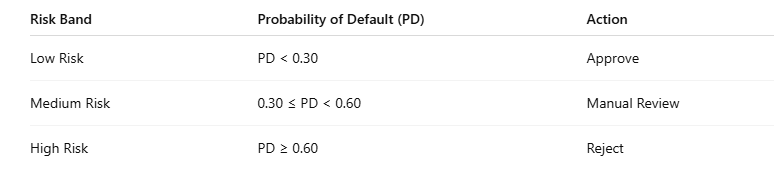


In [50]:
#These are illustrative, not universal.
LOW_RISK_TH = 0.40
HIGH_RISK_TH = 0.50


## iii. APPLY DECISION RULES

In [51]:
#Decision Logic (Reusable)
def assign_decision(pd_value, low_th, high_th):
    if pd_value < low_th:
        return "Approve"
    elif pd_value < high_th:
        return "Review"
    else:
        return "Reject"


In [52]:
# Apply to All Models
preds["logistic_decision"] = preds["logistic_pd"].apply(
    lambda x: assign_decision(x, LOW_RISK_TH, HIGH_RISK_TH)
)

preds["rf_decision"] = preds["rf_pd"].apply(
    lambda x: assign_decision(x, LOW_RISK_TH, HIGH_RISK_TH)
)

preds["xgb_decision"] = preds["xgb_pd"].apply(
    lambda x: assign_decision(x, LOW_RISK_TH, HIGH_RISK_TH)
)

##  iv. PORTFOLIO-LEVEL IMPACT ANALYSIS

#### 1. Decision Distribution

In [53]:
def decision_summary(series):
    return series.value_counts(normalize=True) * 100

print("Logistic Decisions (%):")
print(decision_summary(preds["logistic_decision"]))

print("\nRandom Forest Decisions (%):")
print(decision_summary(preds["rf_decision"]))

print("\nXGBoost Decisions (%):")
print(decision_summary(preds["xgb_decision"]))

Logistic Decisions (%):
logistic_decision
Reject     43.717332
Approve    37.865183
Review     18.417485
Name: proportion, dtype: float64

Random Forest Decisions (%):
rf_decision
Reject     45.430490
Approve    35.886222
Review     18.683289
Name: proportion, dtype: float64

XGBoost Decisions (%):
xgb_decision
Reject     42.424287
Approve    39.849497
Review     17.726216
Name: proportion, dtype: float64


#### 2. Default Rate by Decision Bucket (CRITICAL)
This tells us how clean each bucket is.


In [54]:
def default_rate_by_bucket(df, decision_col):
    return (
        df.groupby(decision_col)["actual_default"]
        .mean()
        .sort_values()
    )

print("Logistic Default Rate by Decision:")
print(default_rate_by_bucket(preds, "logistic_decision"))

print("\nRandom Forest Default Rate by Decision:")
print(default_rate_by_bucket(preds, "rf_decision"))

print("\nXGBoost Default Rate by Decision:")
print(default_rate_by_bucket(preds, "xgb_decision"))

Logistic Default Rate by Decision:
logistic_decision
Approve    0.087127
Review     0.171717
Reject     0.308879
Name: actual_default, dtype: float64

Random Forest Default Rate by Decision:
rf_decision
Approve    0.084491
Review     0.166823
Reject     0.304116
Name: actual_default, dtype: float64

XGBoost Default Rate by Decision:
xgb_decision
Approve    0.086250
Review     0.171855
Reject     0.317782
Name: actual_default, dtype: float64


#### Interpretation

A well-designed decision policy should show:

- **Approve** bucket → lowest default rate
- **Review** bucket → medium default rate
- **Reject** bucket → highest default rate

If the buckets are not ordered this way, the decision thresholds need adjustment, not the model.

## v. BUSINESS COST AT DECISION LEVEL

Let’s now quantify money.

In [55]:
# Assumptions (Same as Phase 5)
COST_DEFAULT = 100_000      # bad loan approved
COST_REJECT_GOOD = 10_000  # good loan rejected


In [56]:
# Cost Calculation Function
def portfolio_cost(df, decision_col):
    cost = 0

    # Approved bad loans → FN
    approved_bad = df[
        (df[decision_col] == "Approve") &
        (df["actual_default"] == 1)
    ].shape[0]

    # Rejected good loans → FP
    rejected_good = df[
        (df[decision_col] == "Reject") &
        (df["actual_default"] == 0)
    ].shape[0]

    cost += approved_bad * COST_DEFAULT
    cost += rejected_good * COST_REJECT_GOOD

    return cost


In [57]:
# Compare Models
log_cost = portfolio_cost(preds, "logistic_decision")
rf_cost  = portfolio_cost(preds, "rf_decision")
xgb_cost = portfolio_cost(preds, "xgb_decision")

print(f"Total Expected Cost (Logistic): ₹{log_cost:,}")
print(f"Total Expected Cost (Random Forest): ₹{rf_cost:,}")
print(f"Total Expected Cost (XGBoost): ₹{xgb_cost:,}")

Total Expected Cost (Logistic): ₹2,125,810,000
Total Expected Cost (Random Forest): ₹2,083,110,000
Total Expected Cost (XGBoost): ₹2,129,450,000


## vi. FINAL DECISION OUTPUT

In [58]:
final_output = preds[[
    "actual_default",
    "logistic_pd", "logistic_decision",
    "rf_pd", "rf_decision",
    "xgb_pd", "xgb_decision"
]]

final_output.to_csv(
    "/kaggle/working/final_loan_decisions.csv",
    index=False
)

print("Final decision file saved.")

Final decision file saved.


# **PHASE 7 — MODEL EXPLAINABILITY (SHAP)**

#### 🎯 Goal
In lending, a model must be able to explain **why** an applicant was flagged as risky, both for regulators and for customers who are rejected.

SHAP (SHapley Additive exPlanations) measures how much each feature pushes a prediction towards or away from default. The summary plot below shows:

* **Feature order:** most influential features at the top
* **Color:** red = high feature value, blue = low feature value
* **Position:** right of zero = increases default risk, left of zero = decreases it

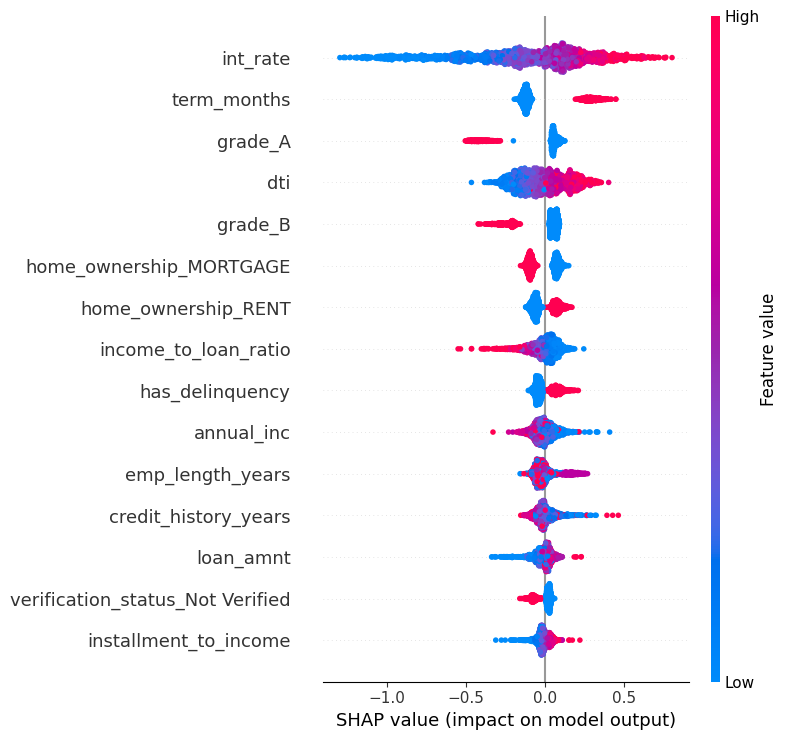

In [61]:
import shap
import xgboost as xgb

# SHAP on the full test set would be slow, so a random sample is used
X_sample = X_test.sample(2000, random_state=42)

# Apply the fitted preprocessing steps, keeping the same (sparse) format used in training
fitted_preprocessor = xgb_model.named_steps["preprocessor"]
X_sample_transformed = fitted_preprocessor.transform(X_sample)

# Clean feature names (remove "num__" / "cat__" prefixes)
feature_names = [name.split("__", 1)[1] for name in fitted_preprocessor.get_feature_names_out()]

# Use XGBoost's built-in SHAP computation so the data is read exactly as during training
booster = xgb_model.named_steps["model"].get_booster()
contribs = booster.predict(xgb.DMatrix(X_sample_transformed), pred_contribs=True)
shap_values = contribs[:, :-1]   # last column is the base value

# Dense copy only for coloring the plot
X_sample_dense = X_sample_transformed.toarray() if hasattr(X_sample_transformed, "toarray") else X_sample_transformed

shap.summary_plot(shap_values, X_sample_dense, feature_names=feature_names, max_display=15)

### 🔎 Key Insights from SHAP

* **Interest rate is the strongest driver:** higher rates push predictions towards default. Since Lending Club sets the rate based on its own risk assessment, this feature partly reflects the lender's existing grading.
* **Loan term matters:** 60-month loans carry clearly higher risk than 36-month loans.
* **Better grades reduce risk:** grade A and B loans push predictions away from default.
* **Debt-to-income ratio (`dti`) is the 4th most influential feature**, confirming the value of adding it during feature engineering.
* **Past delinquencies increase risk**, while a higher income relative to the loan amount reduces it.

These patterns match established credit risk intuition, which increases confidence that the model has learned meaningful relationships rather than noise.